# Tracking
* Script for the rotation experiment
* Script for the pairing experiment
* Dataset for the pairing experiment (potentially same data)
  * Sample a set of representative floes for the sizes covered by the 100 km images
  * Sample a set of representative large floes from the 250 km images
* Description of the use of tracking to refine segmentation results
  * Flagging mismatches? Or changing the shapes?
  * Cross-correlation methods likely need to be future work
* Figure showing pairing for floes within a maximum distance, test out the idea for the image alignment method

In [1]:
using Pkg
Pkg.activate("../scripts/calval")
using IceFloeTracker
using Images
using DataFrames
using CSVFiles
using CairoMakie
using StatsBase

# Load data
dataset = Watkins2026Dataset(;
    url="https://github.com/danielmwatkins/ice-floe-validation-dataset/",
    ref="v0.2",
    cache_dir="/tmp/Watkins2026",
    metadata_path="data/validation_dataset/validation_dataset.csv",
)

  Activating project at `~/Documents/research/manuscripts/calval_tgrs/scripts/calval`


Dataset(GitHubLoader("https://github.com/danielmwatkins/ice-floe-validation-dataset/", "v0.2", "/tmp/Watkins2026"), 378×26 DataFrame
 Row │        case_number  region          satellite  start_date  pass_time    ⋯
     │ Int64  Int64        String          String     Dates.Date  DateTime     ⋯
─────┼──────────────────────────────────────────────────────────────────────────
   1 │     0            1  baffin_bay      terra      2022-09-11  2022-09-11T1 ⋯
   2 │     1            1  baffin_bay      aqua       2022-09-11  2022-09-11T1
   3 │     2            2  baffin_bay      terra      2015-03-12  2015-03-12T1
   4 │     3            2  baffin_bay      aqua       2015-03-12  2015-03-12T1
   5 │     4            3  baffin_bay      terra      2012-04-19  2012-04-19T1 ⋯
   6 │     5            3  baffin_bay      aqua       2012-04-19  2012-04-19T1
   7 │     6            4  baffin_bay      terra      2019-09-25  2019-09-25T1
   8 │     7            4  baffin_bay      aqua       2019-09-25  2

In [ ]:
# check if we have add boundary

In [10]:
# demo for calibration
case = filter(c -> c.case_number == 6, dataset)
sort!(case, :pass_time)

tc_imgs = modis_truecolor.(case)
binary_floes = validated_binary_floes.(case)
passtimes = case.info.pass_time
nothing

In [13]:
using Dates

match_cols = [:scaled_distance, :scaled_boundary_shape_difference]
floe_tracker = FloeTracker(
    filter_function = ChainedFilterFunction(
            [DistanceThresholdFilter(;
               threshold_function=LogLogQuadraticTimeDistanceFunction()
                ),
            BoundaryShapeDifferenceThresholdFilter(; 
                    metric=boundary_modified_hausdorff,
                    threshold_function=PiecewiseLinearThresholdFunction(100, 700, 20, 20)
                ),
            ]
        ),
    matching_function = MinimumWeightMatchingFunction(; columns=match_cols),
    minimum_area = 100,
    maximum_area = 90e3,
    maximum_time_step = Day(2)
)

FloeTracker(ChainedFilterFunction(IceFloeTracker.Tracking.AbstractFloeFilterFunction[DistanceThresholdFilter(:Δt, :Δx, :scaled_distance, LogLogQuadraticTimeDistanceFunction([0.403, 0.988, -0.05], Hour(1), Day(7)), :time_distance_test, IceFloeTracker.Tracking.var"#DistanceThresholdFilter##2#DistanceThresholdFilter##3"()), BoundaryShapeDifferenceThresholdFilter(:area, :boundary, IceFloeTracker.Tracking.boundary_modified_hausdorff, :boundary_shape_difference_test, PiecewiseLinearThresholdFunction(100, 700, 20, 20))]), MinimumWeightMatchingFunction([:scaled_distance, :scaled_boundary_shape_difference], [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]), 100, 90000.0, Day(2))

In [ ]:
# Tracking with distance and boundary shape difference
segmented_imgs = SegmentedImage.(tc_imgs, label_components.(binary_floes))
tracked = floe_tracker(segmented_imgs, passtimes);

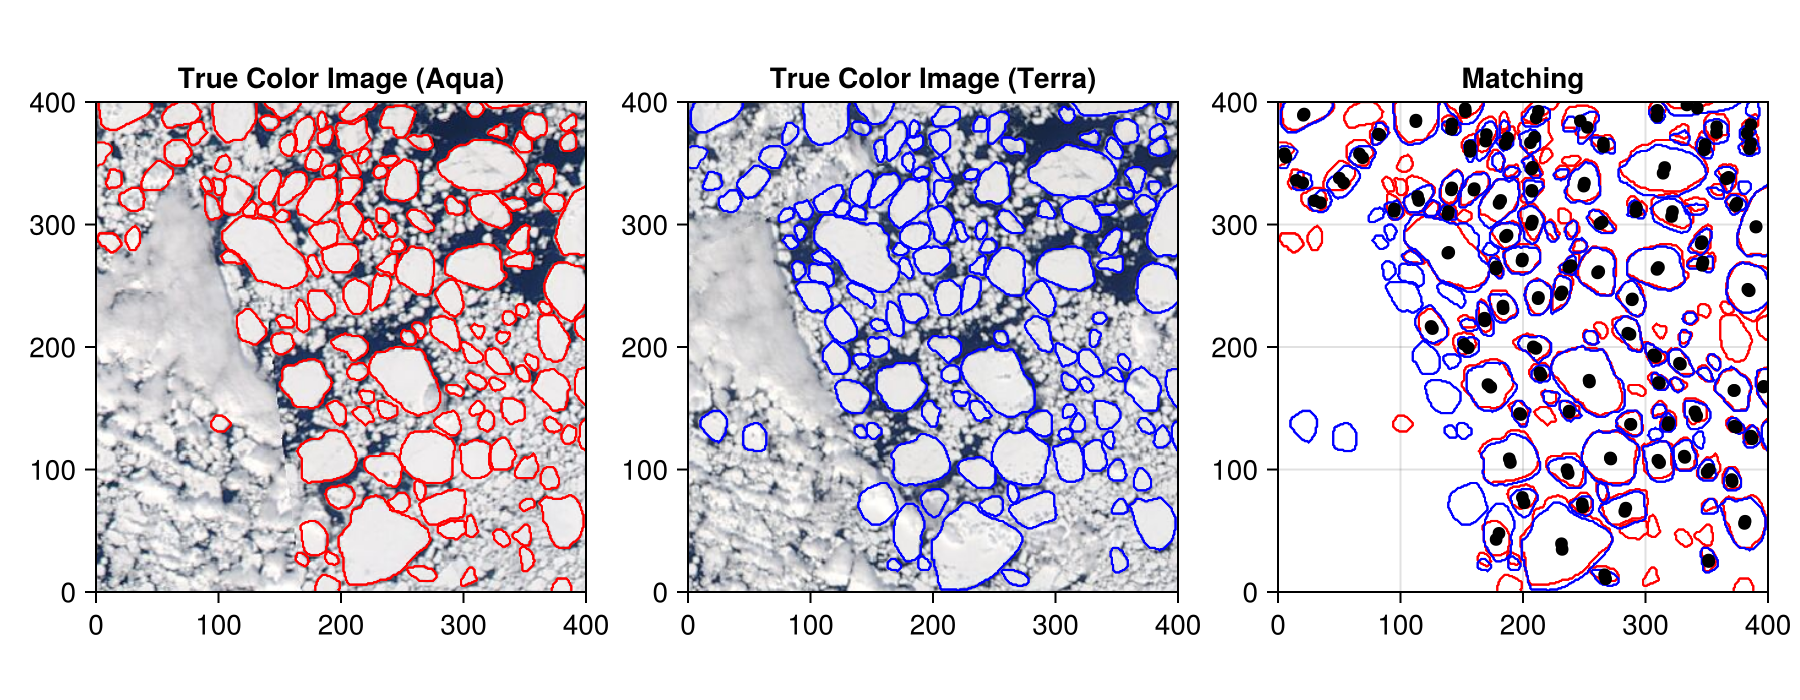

In [19]:
label_imgs = label_components.(binary_floes)
satellites = case.info.satellite
f = Figure(size=(900, 350), title=case)
n, m = size(tc_imgs[1])
a1 = CairoMakie.Axis(f[1,1], title="True Color Image ("*titlecase(satellites[1])*")", aspect=1)
image!(a1, rotr90(tc_imgs[1]))
contour!(a1, rotr90(label_imgs[1]), levels=[0, 1], color=:red)
a2 = CairoMakie.Axis(f[1,2], title="True Color Image ("*titlecase(satellites[2])*")", aspect=1)
image!(a2, rotr90(tc_imgs[2]))
contour!(a2, rotr90(label_imgs[2]), levels=[0, 1], color=:blue)
a3 = CairoMakie.Axis(f[1,3], title="Matching", aspect=1, limits=(0, 400, 0, 400))
contour!(a3, rotr90(label_imgs[1]), levels=[0, 1], color=:red)
contour!(a3, rotr90(label_imgs[2]), levels=[0, 1], color=:blue)

for data in groupby(tracked, :ID)
    # Note: image coordinates start in upper left, unlike plot coordinates. So we subtract the row from the image height.
    scatterlines!(a3, data.col_centroid, n .- data.row_centroid, color=:black)
end

# Label(f[0, :], "Case "*case_number_title*", "*region_title*", "*date_title,
#     fontsize = 24, font = :bold)
f

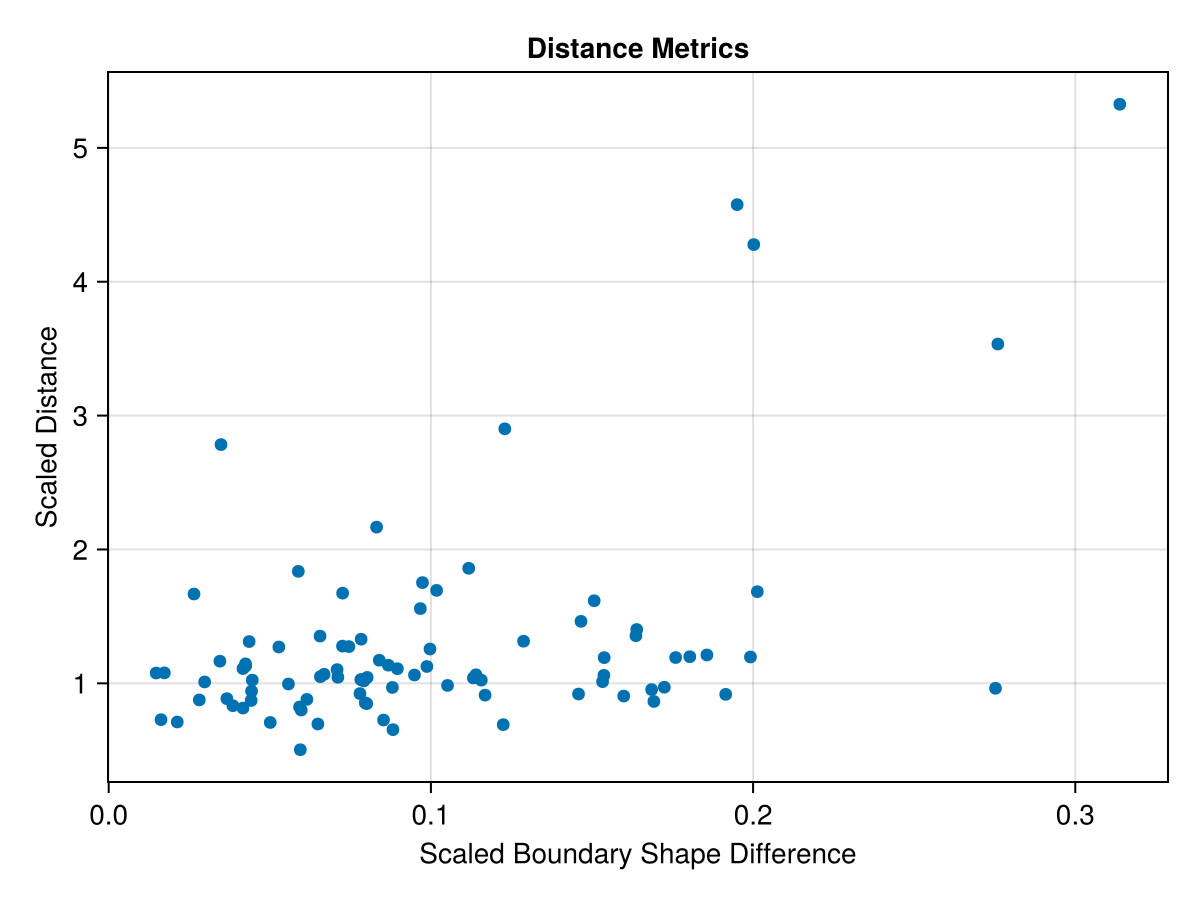

In [22]:
f = CairoMakie.Figure()
ax = CairoMakie.Axis(f[1,1], title="Distance Metrics", ylabel="Scaled Distance", xlabel="Scaled Boundary Shape Difference")
scatter!(ax, tracked[:, :scaled_distance], tracked[:, :scaled_boundary_shape_difference])
f

In [23]:
match_cols = [:scaled_boundary_shape_difference]
floe_tracker = FloeTracker(
    filter_function = ChainedFilterFunction(
            [
            BoundaryShapeDifferenceThresholdFilter(; 
                    metric=boundary_modified_hausdorff,
                    threshold_function=PiecewiseLinearThresholdFunction(100, 700, 20, 20)
                ),
            ]
        ),
    matching_function = MinimumWeightMatchingFunction(; columns=match_cols),
    minimum_area = 100,
    maximum_area = 90e3,
    maximum_time_step = Day(2)
)

FloeTracker(ChainedFilterFunction(IceFloeTracker.Tracking.AbstractFloeFilterFunction[BoundaryShapeDifferenceThresholdFilter(:area, :boundary, IceFloeTracker.Tracking.boundary_modified_hausdorff, :boundary_shape_difference_test, PiecewiseLinearThresholdFunction(100, 700, 20, 20))]), MinimumWeightMatchingFunction([:scaled_boundary_shape_difference], [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]), 100, 90000.0, Day(2))

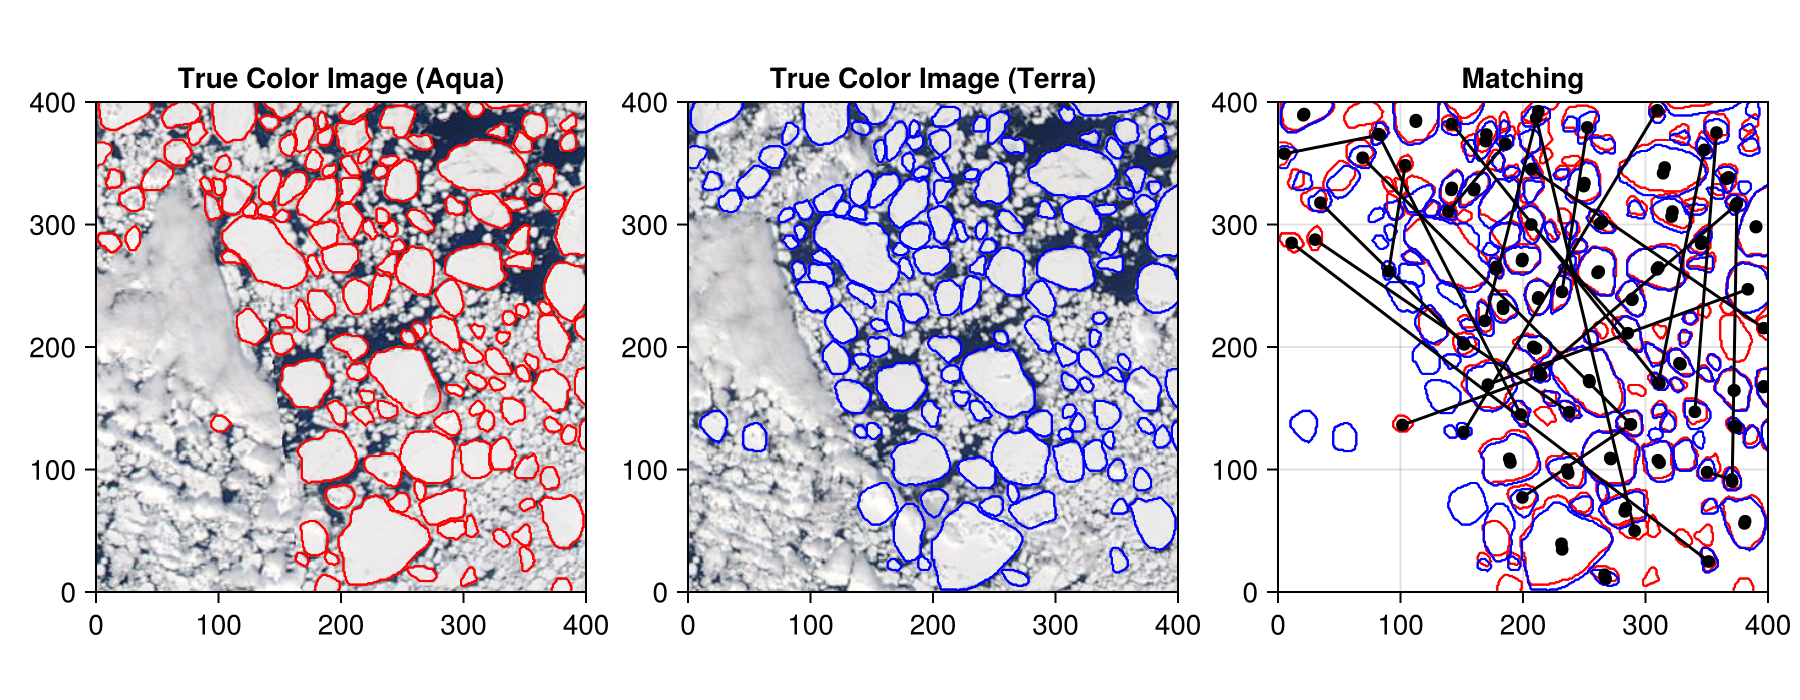

In [24]:
tracked = floe_tracker(segmented_imgs, passtimes)
label_imgs = label_components.(binary_floes)
satellites = case.info.satellite
f = Figure(size=(900, 350), title=case)
n, m = size(tc_imgs[1])
a1 = CairoMakie.Axis(f[1,1], title="True Color Image ("*titlecase(satellites[1])*")", aspect=1)
image!(a1, rotr90(tc_imgs[1]))
contour!(a1, rotr90(label_imgs[1]), levels=[0, 1], color=:red)
a2 = CairoMakie.Axis(f[1,2], title="True Color Image ("*titlecase(satellites[2])*")", aspect=1)
image!(a2, rotr90(tc_imgs[2]))
contour!(a2, rotr90(label_imgs[2]), levels=[0, 1], color=:blue)
a3 = CairoMakie.Axis(f[1,3], title="Matching", aspect=1, limits=(0, 400, 0, 400))
contour!(a3, rotr90(label_imgs[1]), levels=[0, 1], color=:red)
contour!(a3, rotr90(label_imgs[2]), levels=[0, 1], color=:blue)

for data in groupby(tracked, :ID)
    # Note: image coordinates start in upper left, unlike plot coordinates. So we subtract the row from the image height.
    scatterlines!(a3, data.col_centroid, n .- data.row_centroid, color=:black)
end

# Label(f[0, :], "Case "*case_number_title*", "*region_title*", "*date_title,
#     fontsize = 24, font = :bold)
f

In [30]:
names(tracked)

24-element Vector{String}:
 "ID"
 "trajectory_uuid"
 "head_uuid"
 "uuid"
 "area"
 "col_centroid"
 "convex_area"
 "label"
 "major_axis_length"
 "mask"
 "max_col"
 "max_row"
 "min_col"
 "min_row"
 "minor_axis_length"
 "orientation"
 "perimeter"
 "row_centroid"
 "passtime"
 "boundary"
 "psi"
 "boundary_shape_difference"
 "scaled_boundary_shape_difference"
 "w"

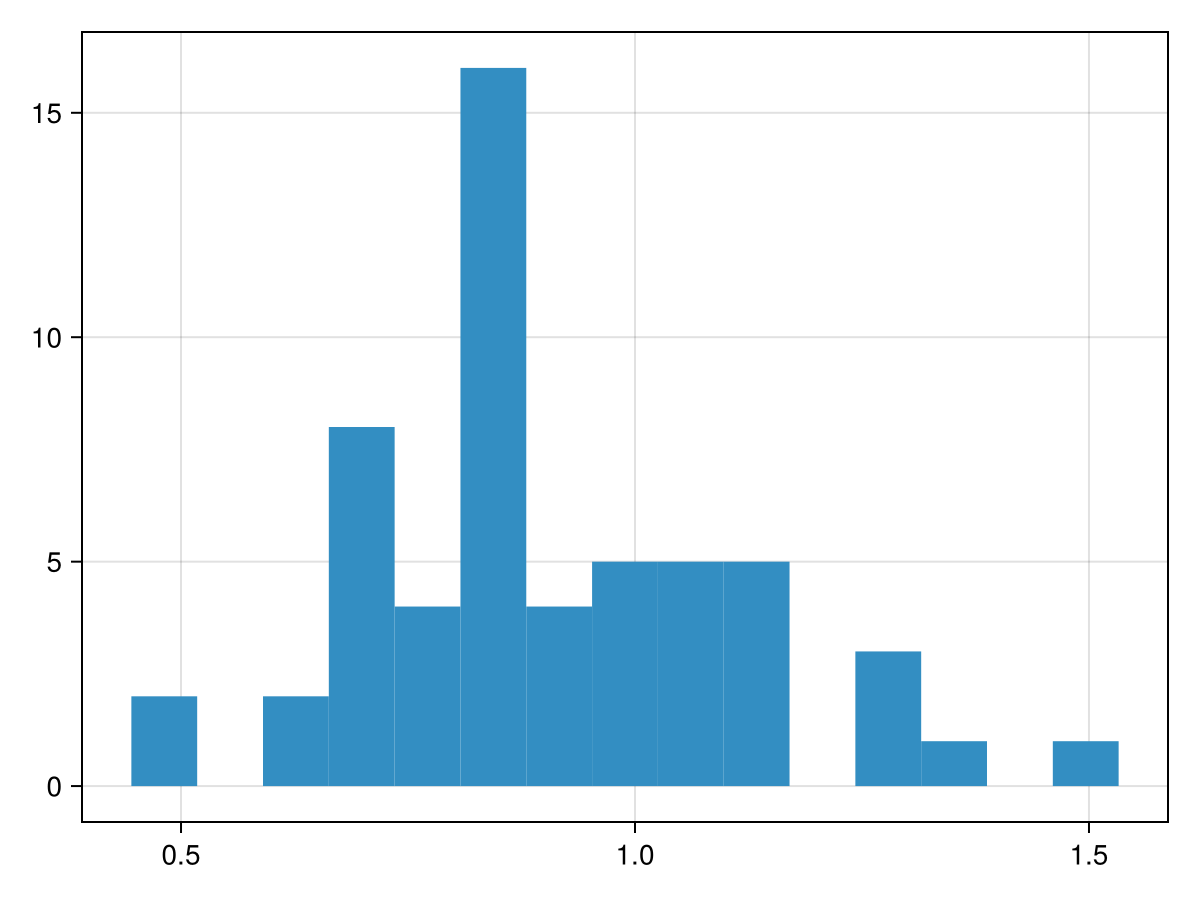

In [28]:
hist(tracked[.!ismissing.(tracked.boundary_shape_difference), :boundary_shape_difference])

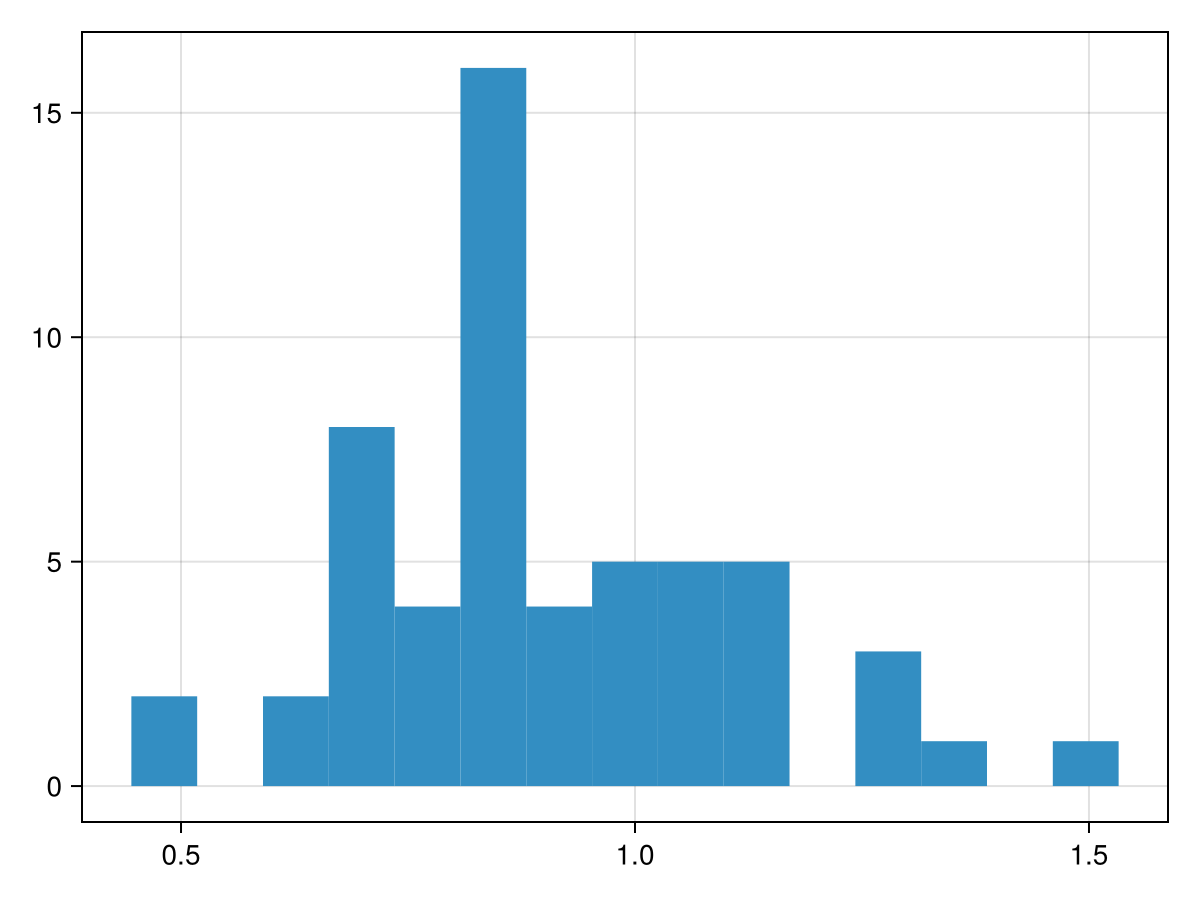

In [29]:
hist(tracked[.!ismissing.(tracked.boundary_shape_difference), :scaled_boundary_shape_difference])